# Avaliação das variáveis: Hotel Booking Demand

Este notebook avalia a base **antes** de qualquer modelo: dicionário de dados, o $Y$ primeiro, faltantes, univariadas, linearidade no logito para as numéricas e V de Cramér para as categóricas. O dicionário consolidado, com a decisão sobre cada variável, está em `../dados/dicionario_hotel_bookings.md`.

**Premissa:** o modelo não pode usar variáveis vazadas. Ele vai ser usado **no momento em que a reserva entra**, para decidir em quais reservas agir (depósito, ligação de confirmação, overbooking). Então só pode usar o que o hotel já sabe nesse momento.

Legendas dos títulos:

* <code style="color:green">verde</code>: explicação
* <code style="color:purple">roxo</code>: comentário, decisão
* <code style="color:gray">cinza</code>: contexto de negócio

**Roteiro**

0. Pacotes e funções
1. Contexto de negócio e leitura da base
2. Dicionário de dados, primeira versão
3. O $Y$ primeiro
4. Qualidade: faltantes, duplicadas e linhas estranhas
5. Vazamento: as evidências, coluna por coluna
6. O fio que liga as anomalias, e o escopo do modelo
7. Univariadas numéricas
8. Linearidade no logito
9. Categóricas: taxa de cancelamento e V de Cramér
10. Redundâncias
11. Decisão por variável
12. Decisões para o grupo

**Como rodar:** abra este notebook de dentro da pasta `analise/` do repositório. A base é lida de `../dados/hotel_bookings.csv`. Usa só pandas, numpy, scipy e matplotlib (o Anaconda já tem tudo).

## 0. Pacotes e funções

In [1]:
import numpy as np                 # contas: np.log, np.where...
import pandas as pd                # tabelas: ler csv, agrupar, cruzar
import matplotlib.pyplot as plt    # gráficos
import scipy.stats as stats        # qui-quadrado
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda v: f'{v:.3f}')
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

### <code style="color:green">Três funções, para não repetir código</code>

- **`taxa_resposta`**: para cada nível de uma variável, quantas reservas (`n`), a % da base, a **taxa de cancelamento** (média do $Y$, que é 0/1) e o **logito** $\ln\left(\frac{p}{1-p}\right)$.
- **`cramer_v`**: qui-quadrado de independência e **V de Cramér**, de 0 (nenhuma associação) a 1 (associação perfeita). Serve tanto para uma categórica contra o $Y$ quanto para duas categóricas entre si.
- **`linearidade_logito`**: ordena o $X$, corta em decis, calcula $p$ e logito de cada decil e desenha os dois. O corte é feito pela **posição** de cada linha, e não pelo valor, para funcionar mesmo com muitos valores repetidos (por exemplo, muita reserva com `lead_time = 0`).

In [2]:
Y = 'is_canceled'

def taxa_resposta(base, variavel, y=Y):
    """Para cada nível: n, % da base, taxa de cancelamento (média do y) e logito."""
    t = base.groupby(variavel, observed=True, dropna=False).agg(n=(y, 'size'), taxa=(y, 'mean'))
    t['pct_base'] = t['n'] / t['n'].sum()
    p = t['taxa'].clip(1e-4, 1 - 1e-4)          # evita log(0) quando a taxa é 0% ou 100%
    t['logito'] = np.log(p / (1 - p))
    return t[['n', 'pct_base', 'taxa', 'logito']]


def cramer_v(base, a, b=Y):
    """Qui-quadrado de independência e V de Cramér entre duas variáveis categóricas."""
    tabela = pd.crosstab(base[a].astype(str), base[b].astype(str))
    chi2, p_valor, gl, esperado = stats.chi2_contingency(tabela)
    return p_valor, np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))


def linearidade_logito(base, x, y=Y, q=10):
    """Ordena x, corta em q faixas de mesmo tamanho, calcula p e logito de cada faixa e desenha."""
    posicao = base[x].rank(method='first')                     # 1, 2, 3... mesmo com valores repetidos
    faixa = pd.qcut(posicao, q, labels=range(1, q + 1))
    t = base.groupby(faixa, observed=True).agg(n=(x, 'size'), min_x=(x, 'min'), max_x=(x, 'max'), p=(y, 'mean'))
    t['logito_p'] = np.log(t['p'] / (1 - t['p']))
    rotulos = [f'{a:g}–{b:g}' for a, b in zip(t['min_x'], t['max_x'])]
    fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
    for eixo, col, nome in zip(eixos, ['p', 'logito_p'], ['p (taxa de cancelamento)', 'logito de p']):
        eixo.plot(range(1, q + 1), t[col], marker='o', color='#2b4fa3')
        eixo.set_xticks(range(1, q + 1), rotulos, rotation=45, ha='right', fontsize=8)
        eixo.set_title(f'{x}: {nome} por decil', fontsize=10)
        eixo.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    return t

## 1. Contexto de negócio e leitura da base

### <code style="color:gray">Contexto Negócio</code>

Dois hotéis em Portugal, um urbano (City Hotel, em Lisboa) e um resort (Resort Hotel, no Algarve), com chegadas entre julho de 2015 e agosto de 2017. Cada linha é **uma reserva**. Fonte: Antonio, Almeida e Nunes (2019), *Hotel booking demand datasets*, Data in Brief.

> **Quais reservas têm mais chance de ser canceladas?**

Isso serve para a Diretoria de Receita decidir **em quais reservas agir**: pedir depósito, ligar para confirmar ou aceitar overbooking. A decisão acontece quando a reserva entra. É esse momento que define o que o modelo pode usar.

In [3]:
hotel = pd.read_csv('../dados/hotel_bookings.csv')
print(hotel.shape)      # (linhas, colunas)
hotel.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03


In [4]:
# tipo de cada coluna no Python, quantos valores diferentes tem e quantos vazios
resumo = pd.DataFrame({
    'tipo_python': hotel.dtypes.astype(str),
    'n_niveis': hotel.nunique(),
    'vazios': hotel.isna().sum(),
    'pct_vazio': hotel.isna().mean() * 100,
})
resumo

,tipo_python,n_niveis,vazios,pct_vazio
hotel,object,2,0,0.000
is_canceled,int64,2,0,0.000
lead_time,int64,479,0,0.000
arrival_date_year,int64,3,0,0.000
arrival_date_month,object,12,0,0.000
arrival_date_week_number,int64,53,0,0.000
arrival_date_day_of_month,int64,31,0,0.000
stays_in_weekend_nights,int64,17,0,0.000
stays_in_week_nights,int64,35,0,0.000
adults,int64,14,0,0.000


### <code style="color:purple">COMENTÁRIOS:</code>

- **119.390 reservas e 32 colunas.** Para o Python, 16 são inteiras, 4 decimais e 12 de texto. Mas o tipo do Python não é o tipo da variável:
  - `is_canceled` e `is_repeated_guest` são números, mas **binárias** (0 ou 1);
  - `agent` e `company` são decimais só porque têm vazios: são **códigos**, ou seja, categóricas;
  - `arrival_date_year` é número, mas não pode entrar como $X$ (ver a seção 2);
  - `children` é decimal por causa de 4 vazios.
- Vazios: `company` (94%), `agent` (14%), `country` (0,4%) e `children` (4 linhas).

## 2. Dicionário de dados, primeira versão

### <code style="color:purple">Dicionário de dados, primeira versão</code>

O que cada variável é e o que esperamos dela **antes** de olhar os dados, com uma coluna que vem da premissa, **quando se sabe**:

- **na reserva**: o hotel já tem a informação quando a reserva entra;
- **pode mudar até a chegada**: existe na reserva, mas a base guarda o valor do fim (chegada ou cancelamento);
- **só no fim**: só existe depois do check-in ou do cancelamento. É vazamento;
- **?**: não sabemos, e os dados vão ter de dizer.

| Variável | Descrição | Tipo | Quando se sabe | Expectativa inicial |
| --- | --- | --- | --- | --- |
| **is_canceled** | **1 = cancelou (inclui no-show), 0 = veio** | **binária (Y)** | | |
| hotel | City Hotel ou Resort Hotel | categórica (2) | na reserva | o urbano deve cancelar mais |
| lead_time | antecedência: dias entre a reserva e a chegada | numérica | na reserva | mais tempo até a chegada, mais chance de mudar de plano |
| arrival_date_year | ano da chegada | numérica (3) | na reserva | não serve como $X$: reserva nova sempre tem ano novo. Serve para separar treino e teste |
| arrival_date_month | mês da chegada | categórica (12) | na reserva | sazonalidade? |
| arrival_date_week_number | semana do ano da chegada | numérica | na reserva | repete o mês |
| arrival_date_day_of_month | dia do mês da chegada | numérica | na reserva | não vemos lógica de negócio |
| stays_in_weekend_nights | noites de sábado ou domingo | contagem | pode mudar até a chegada | lazer × trabalho? |
| stays_in_week_nights | noites de segunda a sexta | contagem | pode mudar até a chegada | |
| adults | adultos | contagem | na reserva | |
| children | crianças | contagem | na reserva | 4 vazios |
| babies | bebês | contagem | na reserva | quase sempre 0 |
| meal | regime: BB, HB, FB, SC, Undefined | categórica (5) | na reserva | pela documentação, Undefined e SC são a mesma coisa (sem refeição) |
| country | país do hóspede | categórica (177) | **?** | pode ser preenchido só no check-in |
| market_segment | segmento: Online TA, Offline TA/TO, Groups, Direct, Corporate e outros | categórica (8) | na reserva | grupos e operadoras devem se comportar diferente |
| distribution_channel | canal: TA/TO, Direct, Corporate, GDS | categórica (5) | na reserva | parecida com o segmento |
| is_repeated_guest | já se hospedou antes | binária | na reserva | cliente que volta cancela menos |
| previous_cancellations | reservas que o cliente já cancelou | contagem | na reserva | quem cancelou antes cancela de novo? |
| previous_bookings_not_canceled | reservas anteriores que o cliente manteve | contagem | na reserva | parecida com `is_repeated_guest` |
| reserved_room_type | tipo de quarto pedido (código anônimo) | categórica (10) | na reserva | o código não significa nada para o público |
| assigned_room_type | tipo de quarto entregue | categórica (12) | **só no fim** | definido no check-in |
| booking_changes | alterações feitas até o check-in ou o cancelamento | contagem | **só no fim** | na hora da reserva, é sempre 0 |
| deposit_type | No Deposit, Non Refund (pago, sem reembolso), Refundable | categórica (3) | na reserva | quem pagou sem reembolso deveria cancelar menos |
| agent | código da agência | categórica (333) | na reserva | muitos níveis |
| company | código da empresa que paga | categórica (352) | na reserva | quase tudo vazio |
| days_in_waiting_list | dias em lista de espera até a confirmação | numérica | na reserva | |
| customer_type | Transient, Transient-Party, Contract, Group | categórica (4) | na reserva | |
| adr | diária média (*average daily rate*) | numérica | na reserva | diária alta, mais cancelamento? |
| required_car_parking_spaces | vagas de garagem pedidas | contagem | **?** | pode ser pedida na chegada |
| total_of_special_requests | pedidos especiais (cama de casal, andar alto...) | contagem | pode mudar até a chegada | quem faz pedido pretende vir? |
| reservation_status | Check-Out, Canceled, No-Show | categórica (3) | **só no fim** | é o próprio $Y$ escrito de outro jeito |
| reservation_status_date | data do último status | data | **só no fim** | é a data do cancelamento, para quem cancelou |

## 3. O $Y$ primeiro

### <code style="color:green">Por que começar pelo Y</code>

A taxa do evento diz o que esperar do modelo e é a base de comparação para as medidas.

In [5]:
print('Taxa geral de cancelamento:', round(hotel[Y].mean(), 4))
display(hotel[Y].value_counts().rename('reservas').to_frame())
taxa_resposta(hotel, 'hotel')

Taxa geral de cancelamento: 0.3704


,reservas
is_canceled,
0,75166
1,44224


,n,pct_base,taxa,logito
hotel,,,,
City Hotel,79330,0.664,0.417,-0.334
Resort Hotel,40060,0.336,0.278,-0.956


### <code style="color:purple">COMENTÁRIOS:</code>

- **37,0%** das reservas foram canceladas (44.224 de 119.390), contando os 1.207 no-shows. Não é um evento raro.
- O hotel urbano cancela 41,7%; o resort, 27,8%.
- O que isso diz sobre as medidas: um modelo ingênuo, que dá 0,37 para toda reserva, já tem MSE de $0{,}37 \times 0{,}63 \approx 0{,}233$. É contra ele que vamos comparar. O lift máximo nos primeiros 10% é $1 / 0{,}37 \approx 2{,}7$.

## 4. Qualidade: faltantes, duplicadas e linhas estranhas

In [6]:
print('Vazios por coluna:')
print(hotel.isna().sum()[hotel.isna().sum() > 0])

Vazios por coluna:
children         4
country        488
agent        16340
company     112593
dtype: int64


In [7]:
print('Linhas que são cópia idêntica de outra (cópias a mais):', hotel.duplicated().sum())
print('Linhas que têm pelo menos uma gêmea na base:', hotel.duplicated(keep=False).sum())

hospedes = hotel['adults'] + hotel['children'].fillna(0) + hotel['babies']
noites = hotel['stays_in_weekend_nights'] + hotel['stays_in_week_nights']
print('Reservas com 0 hóspedes:', (hospedes == 0).sum())
print('Reservas com 0 noites:', (noites == 0).sum())
print('adr negativo:', (hotel['adr'] < 0).sum(), '| adr = 0:', (hotel['adr'] == 0).sum(), '| adr máximo:', hotel['adr'].max())

taxa_resposta(hotel.assign(tem_gemea=hotel.duplicated(keep=False)), 'tem_gemea')

Linhas que são cópia idêntica de outra (cópias a mais): 31994
Linhas que têm pelo menos uma gêmea na base: 40165
Reservas com 0 hóspedes: 180
Reservas com 0 noites: 715
adr negativo: 1 | adr = 0: 1959 | adr máximo: 5400.0


,n,pct_base,taxa,logito
tem_gemea,,,,
False,79225,0.664,0.262,-1.035
True,40165,0.336,0.584,0.339


### <code style="color:purple">COMENTÁRIOS:</code>

- **31.994 linhas são cópia idêntica de outra** (27% da base), e 40.165 linhas têm pelo menos uma gêmea. Como a base não tem número de reserva, não dá para saber se são quartos diferentes de um mesmo grupo (o provável, como veremos na seção 6) ou erro.
- As linhas com gêmea cancelam **58,4%**; as sem gêmea, 26,2%. As cópias não são aleatórias: elas puxam a taxa para cima.
- 180 reservas sem nenhum hóspede, 715 com zero noites (podem ser *day use*), uma diária negativa e uma diária de 5.400 (o percentil 99 é 252).
- `children`: os 4 vazios viram 0 na seção 6.

## 5. Vazamento: as evidências, coluna por coluna

### <code style="color:green">O que é vazamento e como procurar</code>

Uma variável vazada carrega a resposta: ela só existe, ou só tem aquele valor, **porque** a reserva foi cancelada ou não. No papel, ela deixa o modelo ótimo. Na prática, ele é inútil, porque no momento da decisão ninguém tem aquela informação.

O sinal típico é uma taxa de cancelamento **perto de 0% ou de 100%** em algum nível, junto com uma explicação de negócio de que a informação vem depois. Taxa de 0% ou 100% num nível também é **separação perfeita**: a razão de chances vai ao infinito.

### <code style="color:green">5.1 `reservation_status`</code>

In [8]:
pd.crosstab(hotel['reservation_status'], hotel[Y])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


### <code style="color:purple">COMENTÁRIOS:</code>

- Canceled e No-Show são exatamente as 44.224 canceladas; Check-Out, exatamente as 75.166 que vieram. É o $Y$ escrito com outras palavras. **Sai.**

### <code style="color:green">5.2 `reservation_status_date`</code>

In [9]:
# data de chegada, montada a partir das três colunas
chegada = pd.to_datetime(hotel['arrival_date_year'].astype(str) + '-' + hotel['arrival_date_month']
                         + '-' + hotel['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
status_antes_da_chegada = pd.to_datetime(hotel['reservation_status_date']) < chegada
pd.crosstab(status_antes_da_chegada.rename('status antes da chegada'), hotel[Y], margins=True)

is_canceled,0,1,All
status antes da chegada,,,
False,75166,2087,77253
True,0,42137,42137
All,75166,44224,119390


### <code style="color:purple">COMENTÁRIOS:</code>

- **Todas** as 42.137 reservas com status registrado antes da data de chegada foram canceladas: para quem cancelou, essa é a data do cancelamento. **Sai.**

### <code style="color:green">5.3 `assigned_room_type`</code>

In [10]:
quarto_trocado = hotel['assigned_room_type'] != hotel['reserved_room_type']
taxa_resposta(hotel.assign(quarto_trocado=quarto_trocado), 'quarto_trocado')

,n,pct_base,taxa,logito
quarto_trocado,,,,
False,104473,0.875,0.416,-0.341
True,14917,0.125,0.054,-2.868


### <code style="color:purple">COMENTÁRIOS:</code>

- Quando o quarto entregue é diferente do pedido, só **5,4%** cancelam, contra 41,6%. A troca acontece no check-in, e quem cancelou nunca chegou lá para ter o quarto trocado. **Sai.**

### <code style="color:green">5.4 `booking_changes`</code>

In [11]:
taxa_resposta(hotel.assign(alteracoes=hotel['booking_changes'].clip(upper=3)), 'alteracoes')   # 3 = três ou mais

,n,pct_base,taxa,logito
alteracoes,,,,
0,101314,0.849,0.409,-0.370
1,12701,0.106,0.142,-1.797
2,3805,0.032,0.201,-1.378
3,1570,0.013,0.166,-1.617


### <code style="color:purple">COMENTÁRIOS:</code>

- Quem não alterou a reserva cancela 40,9%; quem alterou uma vez, 14,2%. Pela documentação da base, as alterações são contadas até o check-in ou o cancelamento. No momento da reserva, essa coluna é zero para todo mundo. **Sai.**

### <code style="color:green">5.5 `required_car_parking_spaces`</code>

In [12]:
taxa_resposta(hotel.assign(vagas=hotel['required_car_parking_spaces'].clip(upper=2)), 'vagas')   # 2 = duas ou mais

,n,pct_base,taxa,logito
vagas,,,,
0,111974,0.938,0.395,-0.427
1,7383,0.062,0.000,-9.210
2,33,0.000,0.000,-9.210


### <code style="color:purple">COMENTÁRIOS:</code>

- **Nenhuma** das 7.416 reservas com vaga de garagem foi cancelada. É separação perfeita: a razão de chances iria ao infinito. A explicação provável é a mesma do quarto: a vaga é anotada na chegada. **Sai.**

### <code style="color:green">5.6 `country`</code>

In [13]:
pais = pd.Series(np.where(hotel['country'].eq('PRT'), 'Portugal',
                          np.where(hotel['country'].isna(), 'vazio', 'outro')), index=hotel.index, name='pais')
display(taxa_resposta(hotel.assign(pais=pais), 'pais'))

# taxa de cancelamento por segmento, separando Portugal dos outros países
pd.crosstab(hotel['market_segment'], pais, values=hotel[Y], aggfunc='mean')

,n,pct_base,taxa,logito
pais,,,,
Portugal,48590,0.407,0.566,0.267
outro,70312,0.589,0.237,-1.171
vazio,488,0.004,0.137,-1.838


pais,Portugal,outro,vazio
market_segment,,,
Aviation,0.390,0.083,NaN
Complementary,0.134,0.014,0.778
Corporate,0.233,0.020,0.076
Direct,0.206,0.108,0.083
Groups,0.840,0.072,0.000
Offline TA/TO,0.678,0.013,0.559
Online TA,0.453,0.345,0.000
Undefined,1.000,NaN,NaN


### <code style="color:purple">COMENTÁRIOS:</code>

- Portugal cancela 56,6%; os outros países, 23,7%. Parece um efeito forte, mas olhe por segmento:
  - no **Offline TA/TO**, Portugal cancela 67,8% e os outros países, **1,3%**;
  - em **Groups**, 84,0% contra 7,2%;
  - na **agência online**, a diferença quase some: 45,3% contra 34,5%.
- Um efeito desse tamanho só nos segmentos de grupo e operadora combina com o país ser preenchido no check-in: quem não chega fica com o país padrão. Não temos como provar, mas o risco é alto. **Na dúvida, sai.**

### <code style="color:green">5.7 `deposit_type`</code>

In [14]:
display(taxa_resposta(hotel, 'deposit_type'))

nr = hotel[hotel['deposit_type'] == 'Non Refund']
pd.Series({
    'reservas Non Refund': len(nr),
    '% de grupos ou operadoras (Groups, Offline TA/TO)': nr['market_segment'].isin(['Groups', 'Offline TA/TO']).mean() * 100,
    '% no City Hotel': (nr['hotel'] == 'City Hotel').mean() * 100,
    'antecedência mediana, Non Refund (dias)': nr['lead_time'].median(),
    'antecedência mediana, base toda (dias)': hotel['lead_time'].median(),
    '% com algum pedido especial': (nr['total_of_special_requests'] > 0).mean() * 100,
    '% com linha idêntica na base': hotel.duplicated(keep=False)[nr.index].mean() * 100,
}).round(1).to_frame('valor')

,n,pct_base,taxa,logito
deposit_type,,,,
No Deposit,104641,0.876,0.284,-0.926
Non Refund,14587,0.122,0.994,5.049
Refundable,162,0.001,0.222,-1.253


,valor
reservas Non Refund,14587.000
"% de grupos ou operadoras (Groups, Offline TA/TO)",97.200
% no City Hotel,88.200
"antecedência mediana, Non Refund (dias)",183.000
"antecedência mediana, base toda (dias)",69.000
% com algum pedido especial,0.200
% com linha idêntica na base,98.100


### <code style="color:purple">COMENTÁRIOS:</code>

- **99,4%** das reservas Non Refund foram canceladas. É o contrário do esperado (quem pagou sem reembolso deveria vir), e as 14.587 reservas têm um perfil muito particular:
  - 97% de grupos ou operadoras, 88% no hotel urbano;
  - antecedência mediana de 183 dias, contra 69 da base toda;
  - quase nenhuma com pedido especial (0,2%);
  - 98% com uma linha idêntica na base.
- **Leitura provável, não confirmada:** são blocos de quartos reservados por operadoras com meses de antecedência e cancelados em lote, e não hóspedes que pagaram e desistiram.
- Se entrasse no modelo, ele diria que "depósito leva a cancelamento", o oposto da recomendação que queremos fazer. A solução está no escopo (seção 6).

## 6. O fio que liga as anomalias, e o escopo do modelo

### <code style="color:green">Uma tabela por segmento</code>

As anomalias acima (linhas duplicadas, Non Refund, Portugal) parecem se concentrar nas reservas de grupo e de operadora. A tabela abaixo olha cada segmento de uma vez.

In [15]:
fio = hotel.assign(tem_gemea=hotel.duplicated(keep=False)).groupby('market_segment').agg(
    reservas=(Y, 'size'),
    taxa=(Y, 'mean'),
    pct_com_gemea=('tem_gemea', 'mean'),
    pct_non_refund=('deposit_type', lambda s: (s == 'Non Refund').mean()),
    pct_portugal=('country', lambda s: (s == 'PRT').mean()),
    antecedencia_mediana=('lead_time', 'median'),
).sort_values('reservas', ascending=False)
fio

,reservas,taxa,pct_com_gemea,pct_non_refund,pct_portugal,antecedencia_mediana
market_segment,,,,,,
Online TA,56477,0.367,0.146,0.001,0.212,58.000
Offline TA/TO,24219,0.343,0.504,0.207,0.495,109.000
Groups,19811,0.611,0.844,0.463,0.701,162.000
Direct,12606,0.153,0.111,0.002,0.464,16.000
Corporate,5295,0.187,0.278,0.063,0.776,7.000
Complementary,743,0.131,0.101,0.000,0.895,3.000
Aviation,237,0.219,0.080,0.000,0.443,3.000
Undefined,2,1.000,0.000,0.000,1.000,1.500


### <code style="color:purple">COMENTÁRIOS:</code>

- As anomalias andam juntas. **Groups:** 84% das linhas com gêmea, 46% Non Refund, 70% de Portugal, antecedência mediana de 162 dias e 61% de cancelamento. **Offline TA/TO:** 50% com gêmea e 21% Non Refund.
- **Online TA**, o maior segmento (47% das reservas), quase não tem Non Refund (0,1%), tem pouca cópia (15%) e o menor peso de Portugal (21%).
- O fio é o **bloco de quartos de grupo e operadora**: muitas linhas iguais, sem reembolso, com antecedência longa e canceladas juntas.

### <code style="color:green">O escopo: todas as reservas ou só as sem depósito?</code>

In [16]:
def perfil(base):
    return pd.Series({
        'reservas': len(base),
        'taxa de cancelamento': base[Y].mean(),
        'taxa: Portugal': base.loc[base['country'] == 'PRT', Y].mean(),
        'taxa: outros países': base.loc[base['country'] != 'PRT', Y].mean(),
        'taxa: antecedência acima de 365 dias': base.loc[base['lead_time'] > 365, Y].mean(),
        'taxa: já cancelou antes': base.loc[base['previous_cancellations'] > 0, Y].mean(),
        'taxa: esperou na lista': base.loc[base['days_in_waiting_list'] > 0, Y].mean(),
        '% de linhas com gêmea': base.duplicated(keep=False).mean(),
    })

pd.DataFrame({
    'todas as reservas': perfil(hotel),
    'sem depósito (No Deposit)': perfil(hotel[hotel['deposit_type'] == 'No Deposit']),
})

,todas as reservas,sem depósito (No Deposit)
reservas,119390.000,104641.000
taxa de cancelamento,0.370,0.284
taxa: Portugal,0.566,0.389
taxa: outros países,0.236,0.232
taxa: antecedência acima de 365 dias,0.677,0.206
taxa: já cancelou antes,0.916,0.809
taxa: esperou na lista,0.638,0.204
% de linhas com gêmea,0.336,0.246


### <code style="color:purple">COMENTÁRIOS:</code>

- Ficando só com as reservas **sem depósito** (104.641, 88% da base), quase todas as anomalias encolhem:
  - a antecedência acima de 365 dias passa de 67,7% para 20,6% de cancelamento;
  - quem esperou na lista passa de 63,8% para 20,4%;
  - a diferença de Portugal cai de 56,6% × 23,6% para 38,9% × 23,2% (continua alta, e o `country` continua fora);
  - as linhas com gêmea caem de 34% para 25%.
- **Só o "já cancelou antes" continua estranho** (80,9%). Fica na lista de testar.
- O escopo também faz sentido para o negócio: a decisão é **em quais reservas pedir depósito ou ligar para confirmar**, e isso só se aplica a quem ainda não deu garantia de pagamento.
- **Proposta:** modelar as reservas sem depósito (taxa de 28,4%). As 162 Refundable também ficam fora: são poucas e já têm depósito.

In [17]:
ESCOPO = 'sem_deposito'   # troque para 'todas' para refazer as seções 7 a 10 com a base inteira

if ESCOPO == 'sem_deposito':
    base = hotel[hotel['deposit_type'] == 'No Deposit'].copy()
else:
    base = hotel.copy()

base['children'] = base['children'].fillna(0)   # os 4 vazios viram 0 (sem criança)
print(ESCOPO, base.shape, '| taxa de cancelamento:', round(base[Y].mean(), 4))

sem_deposito (104641, 32) | taxa de cancelamento: 0.2838


## 7. Univariadas numéricas

In [18]:
numericas = ['lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
             'previous_cancellations', 'previous_bookings_not_canceled', 'days_in_waiting_list',
             'total_of_special_requests']
base[numericas].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
lead_time,104641.000,88.757,92.992,0.000,14.000,56.000,138.000,281.000,386.000,737.000
adr,104641.000,103.525,49.914,-6.380,70.110,95.500,129.000,198.400,257.000,510.000
stays_in_weekend_nights,104641.000,0.970,1.014,0.000,0.000,1.000,2.000,2.000,4.000,19.000
stays_in_week_nights,104641.000,2.557,1.984,0.000,1.000,2.000,3.000,5.000,10.000,50.000
adults,104641.000,1.863,0.600,0.000,2.000,2.000,2.000,3.000,3.000,55.000
children,104641.000,0.118,0.423,0.000,0.000,0.000,0.000,1.000,2.000,10.000
babies,104641.000,0.009,0.104,0.000,0.000,0.000,0.000,0.000,0.000,10.000
previous_cancellations,104641.000,0.042,0.493,0.000,0.000,0.000,0.000,0.000,1.000,24.000
previous_bookings_not_canceled,104641.000,0.155,1.590,0.000,0.000,0.000,0.000,0.000,4.000,72.000
days_in_waiting_list,104641.000,1.519,14.990,0.000,0.000,0.000,0.000,0.000,58.000,379.000


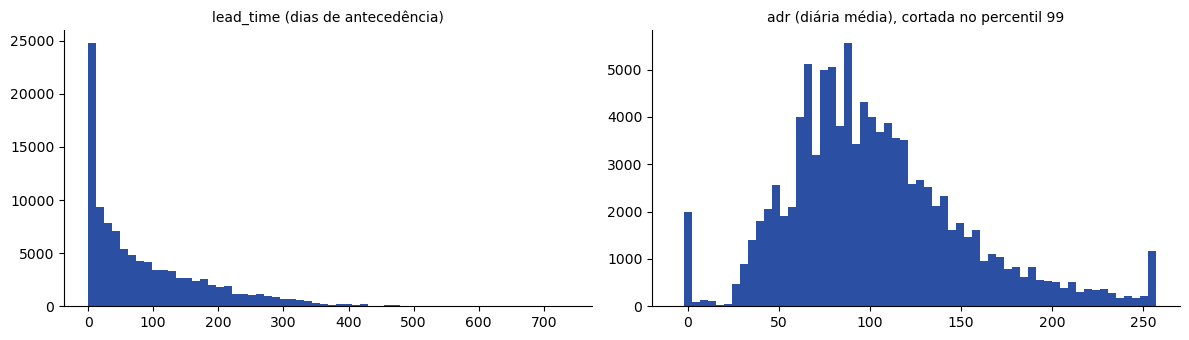

In [19]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
eixos[0].hist(base['lead_time'], bins=60, color='#2b4fa3')
eixos[0].set_title('lead_time (dias de antecedência)', fontsize=10)
eixos[1].hist(base['adr'].clip(upper=base['adr'].quantile(.99)), bins=60, color='#2b4fa3')
eixos[1].set_title('adr (diária média), cortada no percentil 99', fontsize=10)
plt.tight_layout()
plt.show()

### <code style="color:purple">COMENTÁRIOS:</code>

*(Daqui em diante, tudo é calculado no escopo: reservas sem depósito.)*

- **`lead_time`:** mediana de 56 dias; um quarto das reservas tem mais de 138 dias, e o máximo é 737. Cauda longa à direita.
- **`adr`:** mediana de 95,50, percentil 99 de 257 e máximo de 510 (a diária de 5.400 ficou fora com o escopo). Há uma diária negativa (−6,38).
- **As contagens são quase todas zero:** `babies` (99%), `days_in_waiting_list` (98%), `previous_cancellations` (97%) e `previous_bookings_not_canceled` (97%). Variáveis assim funcionam melhor como sim ou não.

## 8. Linearidade no logito

### <code style="color:green">Por que olhar a linearidade?</code>

Uma numérica só entra **como número** se a relação com o **logito de $p$** for linear, porque é isso que o modelo assume ao colocá-la como número. Olhamos a variável sozinha, antes de modelar: ordena o $X$, corta em decis, calcula a taxa $p$ e o logito de cada decil. Se dá "vontade de passar uma reta", entra como número. Se é plana, não importa. Se é curva ou tem degrau, vira faixas.

As contagens com poucos valores (noites, adultos, pedidos especiais...) não cabem em decis: a maioria das linhas tem o mesmo valor. Para elas, olhamos a taxa de cada valor.

### <code style="color:green">Variável: lead_time</code>

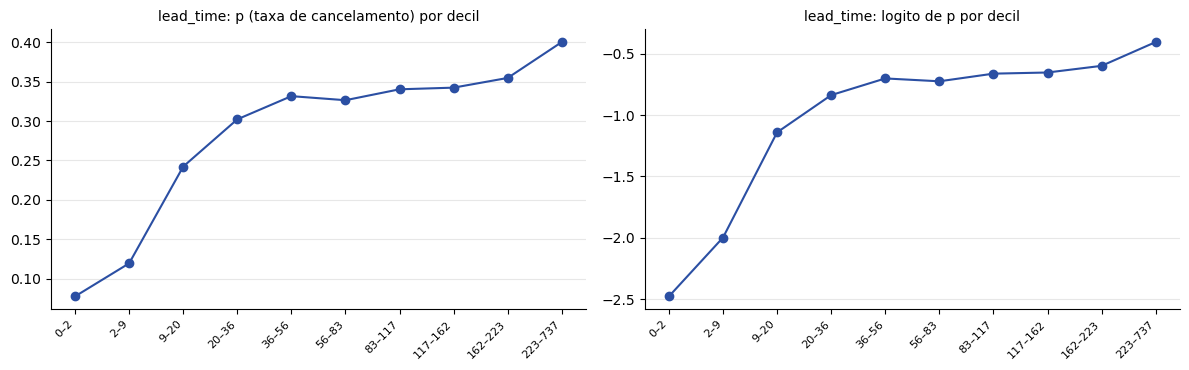

,n,min_x,max_x,p,logito_p
lead_time,,,,,
1,10465,0,2,0.077,-2.478
2,10464,2,9,0.119,-1.998
3,10464,9,20,0.242,-1.140
4,10464,20,36,0.302,-0.836
5,10464,36,56,0.332,-0.700
6,10464,56,83,0.327,-0.724
7,10464,83,117,0.340,-0.661
8,10464,117,162,0.343,-0.652
9,10464,162,223,0.355,-0.598


In [20]:
linearidade_logito(base, 'lead_time')

### <code style="color:purple">COMENTÁRIOS:</code>

- **Não é uma reta.** O logito sobe rápido nos primeiros decis (de −2,5, até 2 dias, para −0,8, entre 20 e 36 dias) e depois quase para (de −0,70 a −0,40, de 36 a 737 dias).
- Na leitura de negócio: a primeira semana e o primeiro mês fazem muita diferença; depois de um mês, mais antecedência pesa pouco.
- Como número, o modelo forçaria uma reta e erraria justamente as reservas de última hora. **Decisão: faixas.**

In [21]:
faixas = [-1, 7, 30, 90, 180, 365, np.inf]
nomes = ['ate_7d', '8_30d', '31_90d', '91_180d', '181_365d', 'mais_365d']
base['lead_time_c'] = pd.cut(base['lead_time'], faixas, labels=nomes)
taxa_resposta(base, 'lead_time_c')

,n,pct_base,taxa,logito
lead_time_c,,,,
ate_7d,19619,0.187,0.092,-2.294
8_30d,18438,0.176,0.260,-1.044
31_90d,27139,0.259,0.322,-0.745
91_180d,22260,0.213,0.349,-0.625
181_365d,15905,0.152,0.398,-0.413
mais_365d,1280,0.012,0.206,-1.348


### <code style="color:purple">COMENTÁRIOS:</code>

- Faixas pensadas para o negócio (semana, mês, trimestre, semestre, ano) dão uma escada clara: **9%** na última semana, 26% no último mês, 32%, 35% e **40%**.
- A faixa acima de 365 dias (1.280 reservas) quebra a escada, com 20,6%. **Proposta:** juntar com a de 181 a 365 dias numa faixa "mais de 180 dias", e olhar quem são essas reservas antes de fechar.
- É a variável permitida mais forte da base (V de Cramér de 0,23, seção 9), e já é o gráfico do slide 3: "risco por faixa de antecedência".

### <code style="color:green">Variável: adr</code>

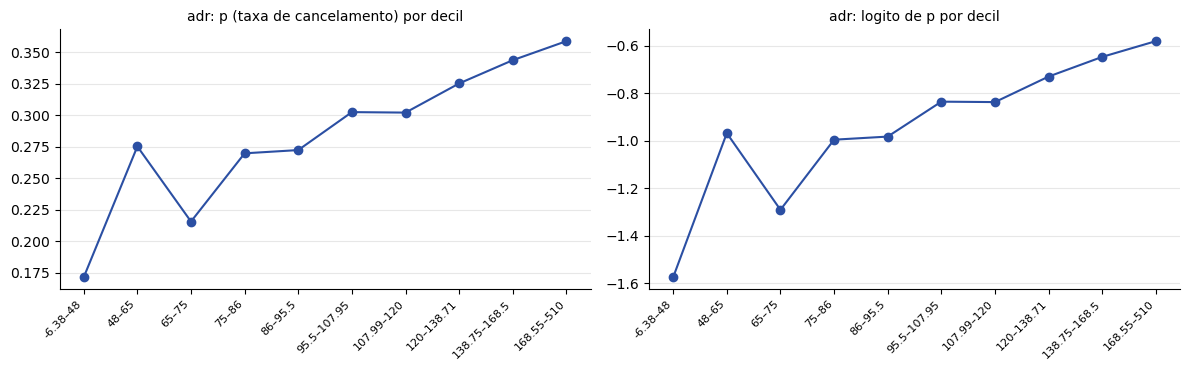

,n,min_x,max_x,p,logito_p
adr,,,,,
1,10465,-6.380,48.000,0.172,-1.574
2,10464,48.000,65.000,0.275,-0.968
3,10464,65.000,75.000,0.216,-1.290
4,10464,75.000,86.000,0.270,-0.995
5,10464,86.000,95.500,0.272,-0.982
6,10464,95.500,107.950,0.303,-0.835
7,10464,107.990,120.000,0.302,-0.837
8,10464,120.000,138.710,0.325,-0.729
9,10464,138.750,168.500,0.344,-0.647


In [22]:
linearidade_logito(base, 'adr')

### <code style="color:purple">COMENTÁRIOS:</code>

- Sobe de forma quase contínua: de 17% de cancelamento (diárias até 48) para 36% (acima de 168), com o logito indo de −1,6 a −0,6 e um tropeço no 3º decil.
- Dá alguma vontade de passar uma reta, principalmente do 4º decil em diante. **Decisão: candidata a entrar como número**, com faixas como alternativa se o modelo mostrar problema.
- Cuidado na leitura: a diária sobe com o número de hóspedes (correlação de 0,34 com crianças e 0,26 com adultos, seção 10) e com a temporada. Não é só "preço alto faz cancelar".

### <code style="color:green">As contagens: taxa por valor</code>

In [23]:
contagens = ['stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
             'total_of_special_requests', 'previous_cancellations', 'previous_bookings_not_canceled']
for var in contagens:
    teto = max(int(base[var].quantile(.99)), 1)
    print(f'\n--- {var} (o último valor, {teto}, soma tudo de {teto} para cima)')
    display(taxa_resposta(base.assign(**{var: base[var].clip(upper=teto)}), var))


--- stays_in_weekend_nights (o último valor, 4, soma tudo de 4 para cima)


,n,pct_base,taxa,logito
stays_in_weekend_nights,,,,
0,43589,0.417,0.256,-1.067
1,26994,0.258,0.278,-0.955
2,30679,0.293,0.322,-0.744
3,1235,0.012,0.340,-0.663
4,2144,0.020,0.342,-0.655



--- stays_in_week_nights (o último valor, 10, soma tudo de 10 para cima)


,n,pct_base,taxa,logito
stays_in_week_nights,,,,
0,7120,0.068,0.199,-1.394
1,26989,0.258,0.244,-1.132
2,26681,0.255,0.296,-0.868
3,19416,0.186,0.296,-0.865
4,8989,0.086,0.325,-0.731
5,10671,0.102,0.325,-0.729
6,1483,0.014,0.382,-0.483
7,1028,0.010,0.313,-0.785
8,644,0.006,0.323,-0.740



--- adults (o último valor, 3, soma tudo de 3 para cima)


,n,pct_base,taxa,logito
adults,,,,
0,403,0.004,0.270,-0.992
1,20235,0.193,0.195,-1.417
2,77748,0.743,0.302,-0.838
3,6255,0.060,0.346,-0.637


... (6 outputs left out)


--- previous_cancellations (o último valor, 1, soma tudo de 1 para cima)


,n,pct_base,taxa,logito
previous_cancellations,,,,
0,101803,0.973,0.269,-0.999
1,2838,0.027,0.809,1.444



--- previous_bookings_not_canceled (o último valor, 4, soma tudo de 4 para cima)


,n,pct_base,taxa,logito
previous_bookings_not_canceled,,,,
0,101036,0.966,0.292,-0.886
1,1536,0.015,0.051,-2.928
2,580,0.006,0.055,-2.841
3,333,0.003,0.051,-2.923
4,1156,0.011,0.061,-2.727


In [24]:
# 97% das reservas não passaram pela lista de espera; olhamos como sim ou não
taxa_resposta(base.assign(esperou=base['days_in_waiting_list'] > 0), 'esperou')

,n,pct_base,taxa,logito
esperou,,,,
False,102974,0.984,0.285,-0.919
True,1667,0.016,0.204,-1.362


### <code style="color:purple">COMENTÁRIOS:</code>

- **Noites** (`stays_in_weekend_nights`, `stays_in_week_nights`): sobem devagar (de 26% para 34% nas de fim de semana; de 20% para cerca de 33% nas de semana) e são correlacionadas entre si (0,52). Fracas. **Testar** a soma das duas, em faixas.
- **`adults`:** 1 adulto cancela 19,5%; 2, 30,2%; 3 ou mais, 34,6%. **Testar** como sozinho × acompanhado. As 403 reservas sem adulto são problema de cadastro.
- **`children`:** de 28% (sem criança) para 42% (duas ou mais). Fraca; **testar** como sim ou não.
- **`babies`:** 99% zero. **Sai.**
- **`total_of_special_requests`:** o degrau está entre nenhum pedido (34,3%) e algum pedido (cerca de 22%). Vira **`fez_pedido`**, sim ou não. Mas o pedido pode ter sido feito depois da reserva, perto da chegada. **Testar com e sem.**
- **`previous_cancellations`:** quem já cancelou alguma vez cancela **80,9%**, contra 26,9%. Forte demais para uma informação de histórico; na base toda, nos grupos e operadoras, chega a 99–100%. **Testar com e sem**: se a AUC subir muito só por causa dela, desconfiar.
- **`previous_bookings_not_canceled`:** quem já veio e não cancelou cancela cerca de 5%, contra 29%. Vira **`ja_veio`**, sim ou não (ver a redundância na seção 10).
- **`days_in_waiting_list`:** no escopo, quem esperou cancela 20,4%, contra 28,5%, e são só 1,6% das reservas. Fraca (V de 0,02 na seção 9). **Sai.**

### <code style="color:green">Variáveis de data: dia do mês e semana do ano</code>

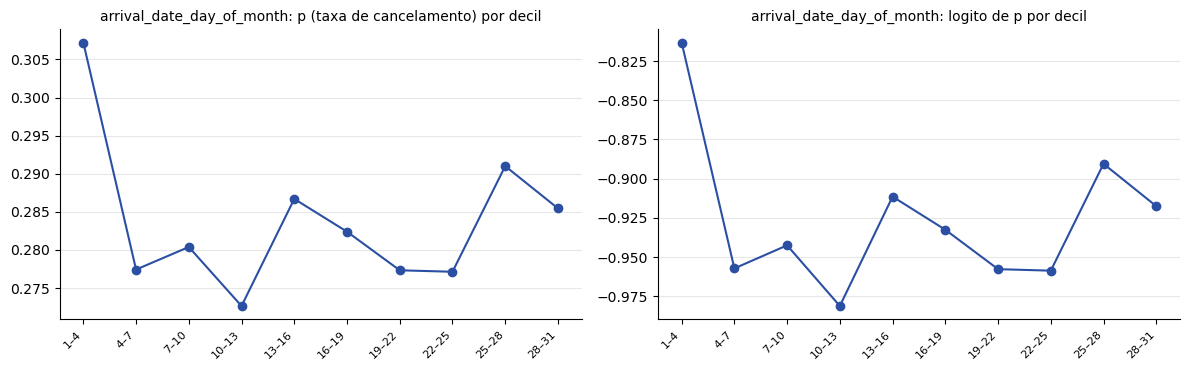

,n,min_x,max_x,p,logito_p
arrival_date_day_of_month,,,,,
1,10465,1,4,0.307,-0.813
2,10464,4,7,0.277,-0.957
3,10464,7,10,0.280,-0.943
4,10464,10,13,0.273,-0.981
5,10464,13,16,0.287,-0.911
6,10464,16,19,0.282,-0.933
7,10464,19,22,0.277,-0.958
8,10464,22,25,0.277,-0.959
9,10464,25,28,0.291,-0.891


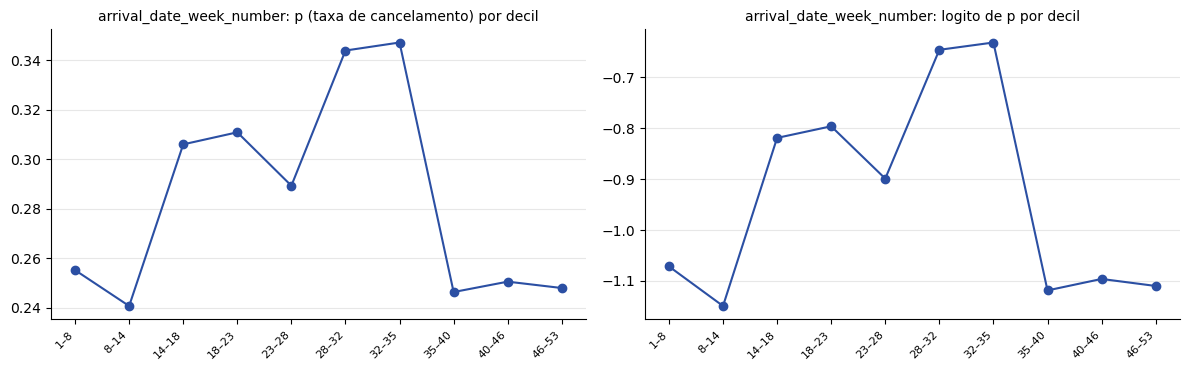

,n,min_x,max_x,p,logito_p
arrival_date_week_number,,,,,
1,10465,1,8,0.255,-1.071
2,10464,8,14,0.241,-1.149
3,10464,14,18,0.306,-0.819
4,10464,18,23,0.311,-0.796
5,10464,23,28,0.289,-0.899
6,10464,28,32,0.344,-0.646
7,10464,32,35,0.347,-0.631
8,10464,35,40,0.246,-1.119
9,10464,40,46,0.250,-1.096


In [25]:
display(linearidade_logito(base, 'arrival_date_day_of_month'))
linearidade_logito(base, 'arrival_date_week_number')

### <code style="color:purple">COMENTÁRIOS:</code>

- **Dia do mês:** plano, entre 27% e 31%. **Sai.**
- **Semana do ano:** tem padrão de temporada (mais cancelamento entre as semanas 28 e 35, o verão europeu), mas não é linear e repete o mês. **Sai.** A temporada entra pelo mês (seção 9).

## 9. Categóricas: taxa de cancelamento e V de Cramér

### <code style="color:green">Como ler</code>

Para cada categórica, o qui-quadrado testa se ela e o cancelamento são independentes, e o **V de Cramér** diz o tamanho da associação, de 0 a 1. Com mais de 100 mil linhas, quase tudo dá p-valor zero, então o que importa é o V. Incluímos, só para comparar, as versões binárias das contagens e as colunas vazadas.

In [26]:
base['pais'] = np.where(base['country'].eq('PRT'), 'Portugal', 'outro')
base['fez_pedido'] = base['total_of_special_requests'] > 0
base['ja_cancelou'] = base['previous_cancellations'] > 0
base['esperou'] = base['days_in_waiting_list'] > 0
base['quarto_trocado'] = base['assigned_room_type'] != base['reserved_room_type']
base['tem_vaga'] = base['required_car_parking_spaces'] > 0
base['alterou'] = base['booking_changes'] > 0

situacao = {
    'hotel': 'na reserva', 'market_segment': 'na reserva', 'distribution_channel': 'na reserva',
    'customer_type': 'na reserva', 'meal': 'na reserva', 'reserved_room_type': 'na reserva',
    'arrival_date_month': 'na reserva', 'is_repeated_guest': 'na reserva', 'lead_time_c': 'na reserva',
    'fez_pedido': 'pode mudar até a chegada', 'ja_cancelou': '? (ver seção 6)', 'esperou': '? (ver seção 6)',
    'pais': '? (ver 5.6)', 'tem_vaga': 'vazada (5.5)', 'quarto_trocado': 'vazada (5.3)',
    'alterou': 'vazada (5.4)', 'reservation_status': 'vazada (5.1)',
}
v = pd.DataFrame([(var, *cramer_v(base, var), s) for var, s in situacao.items()],
                 columns=['variavel', 'p_valor', 'V_cramer', 'quando_se_sabe'])
v.sort_values('V_cramer', ascending=False).reset_index(drop=True)

,variavel,p_valor,V_cramer,quando_se_sabe
0,reservation_status,0.000,1.000,vazada (5.1)
1,lead_time_c,0.000,0.226,na reserva
2,market_segment,0.000,0.213,na reserva
3,quarto_trocado,0.000,0.211,vazada (5.3)
4,ja_cancelou,0.000,0.194,? (ver seção 6)
5,tem_vaga,0.000,0.174,vazada (5.5)
6,pais,0.000,0.163,? (ver 5.6)
7,distribution_channel,0.000,0.142,na reserva
8,fez_pedido,0.000,0.139,pode mudar até a chegada
9,alterou,0.000,0.133,vazada (5.4)


### <code style="color:purple">COMENTÁRIOS:</code>

- Entre as permitidas, as mais fortes são a **antecedência em faixas (0,23)** e o **segmento (0,21)**. Depois vêm o canal (0,14, redundante com o segmento), o tipo de cliente (0,09), o mês (0,09), o regime de refeição (0,08), o cliente que volta (0,07) e o hotel (0,06).
- Repare onde caem as vazadas: o quarto trocado (0,21), a vaga (0,17) e a alteração (0,13) estariam entre as mais fortes do modelo. É por isso que vazamento é perigoso: o modelo ficaria bonito no papel.
- As suspeitas também são fortes: já cancelou (0,19), país (0,16) e fez pedido (0,14). Por isso a decisão sobre elas pesa.
- Lista de espera (0,02), tipo de quarto (0,05) e hotel (0,06) quase não separam.

In [27]:
for var in ['market_segment', 'customer_type', 'meal', 'reserved_room_type', 'is_repeated_guest']:
    print(f'\n--- {var}')
    display(taxa_resposta(base, var).sort_values('n', ascending=False))

meses = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August',
         'September', 'October', 'November', 'December']
print('\n--- arrival_date_month')
taxa_resposta(base, 'arrival_date_month').reindex(meses)


--- market_segment


,n,pct_base,taxa,logito
market_segment,,,,
Online TA,56403,0.539,0.366,-0.548
Offline TA/TO,19209,0.184,0.172,-1.571
Direct,12581,0.120,0.152,-1.717
Groups,10509,0.100,0.283,-0.930
Corporate,4957,0.047,0.137,-1.841
Complementary,743,0.007,0.131,-1.896
Aviation,237,0.002,0.219,-1.269
Undefined,2,0.000,1.000,9.210



--- customer_type


,n,pct_base,taxa,logito
customer_type,,,,
Transient,76684,0.733,0.308,-0.812
Transient-Party,23858,0.228,0.224,-1.245
Contract,3530,0.034,0.203,-1.369
Group,569,0.005,0.104,-2.157



--- meal


,n,pct_base,taxa,logito
meal,,,,
BB,79722,0.762,0.277,-0.959
HB,12754,0.122,0.261,-1.043
SC,10640,0.102,0.372,-0.524
Undefined,1021,0.010,0.135,-1.856
FB,504,0.005,0.377,-0.502


... (2 outputs left out)


--- is_repeated_guest


,n,pct_base,taxa,logito
is_repeated_guest,,,,
0,100899,0.964,0.289,-0.898
1,3742,0.036,0.131,-1.888



--- arrival_date_month


,n,pct_base,taxa,logito
arrival_date_month,,,,
January,5310,0.051,0.225,-1.236
February,7238,0.069,0.258,-1.057
March,8646,0.083,0.240,-1.150
April,9347,0.089,0.303,-0.833
May,10089,0.096,0.299,-0.854
June,9134,0.087,0.299,-0.852
July,11980,0.114,0.339,-0.666
August,12962,0.124,0.334,-0.690
September,8549,0.082,0.253,-1.083


### <code style="color:purple">COMENTÁRIOS:</code>

- **`market_segment`:** Online TA cancela 36,6%; Groups, 28,3%; Offline TA/TO, 17,2%; Direct, 15,2%; Corporate, 13,7%. Complementary (cortesia, 743), Aviation (237) e Undefined (2) têm pouco volume: **juntar em "Outros"**.
- **`customer_type`:** Transient 30,8%, Transient-Party 22,4%, Contract 20,3% e Group 10,4% (só 569). Como está, ou Transient contra os outros três.
- **`meal`:** SC (sem refeição) cancela 37,2%, e BB, 27,7%. A documentação diz que Undefined é o mesmo que SC, mas ele cancela 13,5%: os dois não se comportam igual. Fraca; **testar**.
- **`reserved_room_type`:** entre 27% e 41%, com códigos anônimos. Fraca e impossível de explicar para o público. **Sai.**
- **`is_repeated_guest`:** quem volta cancela 13,1%, contra 28,9%. Ver a redundância na seção 10.
- **`arrival_date_month`:** três patamares. Julho e agosto perto de 34%; abril a junho perto de 30%; setembro a março entre 22% e 27%. **Agrupar em três temporadas.**

## 10. Redundâncias

In [28]:
print('V de Cramér entre segmento e canal:', round(cramer_v(base, 'market_segment', 'distribution_channel')[1], 3))
pd.crosstab(base['market_segment'], base['distribution_channel'])

V de Cramér entre segmento e canal: 0.703


distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
market_segment,,,,,
Aviation,227,0,0,10,0
Complementary,89,576,0,78,0
Corporate,4528,167,0,262,0
Direct,90,12254,1,234,2
Groups,960,1003,0,8546,0
Offline TA/TO,207,16,45,18941,0
Online TA,34,133,147,56088,1
Undefined,0,0,0,0,2


In [29]:
print('V de Cramér entre is_repeated_guest e já ter reserva mantida:',
      round(cramer_v(base.assign(ja_veio=base['previous_bookings_not_canceled'] > 0), 'is_repeated_guest', 'ja_veio')[1], 3))
pd.crosstab(base['is_repeated_guest'], base['previous_bookings_not_canceled'] > 0)

V de Cramér entre is_repeated_guest e já ter reserva mantida: 0.763


previous_bookings_not_canceled,False,True
is_repeated_guest,,
0,100126,773
1,910,2832


In [30]:
base[['lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'total_of_special_requests']].corr()

,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,adults,children,total_of_special_requests
lead_time,1.000,0.001,0.183,0.252,0.134,-0.001,0.009
adr,0.001,1.000,0.039,0.062,0.264,0.343,0.166
stays_in_weekend_nights,0.183,0.039,1.000,0.522,0.094,0.037,0.046
stays_in_week_nights,0.252,0.062,0.522,1.000,0.098,0.038,0.050
adults,0.134,0.264,0.094,0.098,1.000,0.029,0.123
children,-0.001,0.343,0.037,0.038,0.029,1.000,0.058
total_of_special_requests,0.009,0.166,0.046,0.050,0.123,0.058,1.000


### <code style="color:purple">COMENTÁRIOS:</code>

- **Segmento × canal:** V de Cramér de 0,70. Online TA e Offline TA/TO estão quase todos no canal TA/TO, e Direct no Direct. O segmento diz mais (separa agência online de operadora). **Fica o segmento; o canal sai.**
- **`is_repeated_guest` × já ter vindo sem cancelar:** V de 0,76. **Fica uma só.** Propomos a `ja_veio` (feita a partir de `previous_bookings_not_canceled`), que separa mais: 5% × 29%, contra 13% × 29%.
- **Numéricas:** nenhuma correlação passa de 0,7. A maior é entre as noites de fim de semana e de semana (0,52), mais um motivo para somá-las.

## 11. Decisão por variável

### <code style="color:purple">Dicionário de dados atualizado</code>

| Variável | Decisão | Como entra | Por quê |
| --- | --- | --- | --- |
| `lead_time` | **entra** | faixas: até 7 dias, 8–30, 31–90, 91–180, mais de 180 | a mais forte das permitidas (V = 0,23); não é reta no logito |
| `market_segment` | **entra** | Online TA, Offline TA/TO, Groups, Direct, Corporate, Outros | V = 0,21 |
| `customer_type` | **entra** | como está, ou Transient × outros | V = 0,09 |
| `arrival_date_month` | **entra** | três temporadas: jul–ago, abr–jun, set–mar | V = 0,09, com três patamares |
| `hotel` | **entra** | como está | fraca (V = 0,06), mas é o contexto do negócio |
| `adr` | **entra** | número (faixas, se der problema) | logito sobe quase em linha |
| `previous_bookings_not_canceled` | **entra** | binária `ja_veio` | 5% × 29%; substitui `is_repeated_guest` |
| `total_of_special_requests` | testar | binária `fez_pedido` | 22% × 34%; o pedido pode ter vindo depois da reserva |
| `previous_cancellations` | testar | binária `ja_cancelou` | 81% × 27%: forte demais, suspeita de contagem dentro do bloco |
| `adults` | testar | binária: sozinho × acompanhado | 20% × 30% |
| `children` | testar | binária | fraca |
| `stays_in_weekend_nights` + `stays_in_week_nights` | testar | soma das noites, em faixas | fracas e correlacionadas (0,52) |
| `meal` | testar | SC × com refeição | fraca (V = 0,08) |
| `deposit_type` | **vira o escopo** | o modelo usa só as reservas No Deposit | Non Refund cancela 99,4% (blocos de grupo); a ação só vale para quem não deu garantia |
| `reservation_status` | **sai: vazada** | | é o próprio $Y$ |
| `reservation_status_date` | **sai: vazada** | | antes da chegada, 100% cancelada |
| `assigned_room_type` | **sai: vazada** | | definido no check-in |
| `booking_changes` | **sai: vazada** | | contado até o check-in ou o cancelamento |
| `required_car_parking_spaces` | **sai: vazada** | | nenhuma das 7.416 reservas com vaga cancelou |
| `country` | **sai: suspeita** | | o efeito aparece só em grupos e operadoras; provável preenchimento no check-in |
| `arrival_date_year` | sai | separa treino e teste | reserva futura sempre tem ano novo |
| `arrival_date_day_of_month` | sai | | plana |
| `arrival_date_week_number` | sai | | repete o mês |
| `distribution_channel` | sai | | redundante com o segmento (V = 0,70) |
| `is_repeated_guest` | sai | | redundante com `ja_veio` (V = 0,76) |
| `reserved_room_type` | sai | | fraca e com código anônimo |
| `babies` | sai | | 99% zero |
| `days_in_waiting_list` | sai | | fraca no escopo (V = 0,02) |
| `agent` | sai, por ora | | 333 códigos sem significado para o público |
| `company` | sai | | 94% vazio |

**Resumo:** das 31 variáveis além do $Y$, **7 entram**, **6 vão para teste** (com 7 colunas, porque as noites viram uma só), **6 saem por vazamento ou suspeita**, **1 vira o escopo** e **10 saem** por serem fracas, redundantes ou sem uso.

## 12. Decisões para o grupo

### <code style="color:purple">O que precisamos decidir juntos</code>

1. **Escopo:** modelar só as reservas sem depósito? *Proposta: sim.* A frase da apresentação passa a ser "entre as reservas sem garantia de pagamento, 28% são canceladas".
2. **Duplicadas:** manter ou remover? *Proposta: manter.* Como o teste é o ano de 2017, linhas idênticas têm a mesma data de chegada e não ficam ao mesmo tempo no treino e no teste. Rodar uma versão sem duplicadas só para conferir.
3. **As variáveis de "testar":** rodar o modelo com e sem cada uma. Se a AUC subir muito só por causa de `ja_cancelou` ou de `fez_pedido`, desconfiar e deixar fora.
4. **Faixas de antecedência:** cinco faixas, juntando "mais de 365" com "181 a 365"?
5. **Limpeza:** tirar as reservas sem hóspede (180 na base toda) e decidir sobre as 715 com zero noites.
6. **Validação:** treino com as chegadas de 2015 e 2016, teste com as de 2017 (só de janeiro a agosto).
7. **Anexo técnico:** a tabela acima, com o que saiu e por quê, já é metade do anexo.